In [2]:
import os
import numpy as np
import scipy.io as sio
from tqdm import tqdm
import h5py

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader

from sklearn.model_selection import train_test_split

import matplotlib.pyplot as plt

import sys
sys.path.append("..") 

device = torch.device(
    "cuda" if torch.cuda.is_available()
    else "cpu"
)

print(device)

cuda


In [3]:
from processing import  load_UCI_dataset, plot_regression_results, print_metrics, plot_convtran_loss
from UCI.pre_processing import  create_dataloaders

In [4]:
BASE_DIR = "/data1/yashvi_bhuva/BP_estimation_using_PPG/VitalDB/ML/non_fiducial_features/5sec_0overlap/vitaldb_checkpoints"
X_train, y_train, X_val, y_val, X_test, y_test = load_UCI_dataset(WINDOW_SIZE= 625, STEP_SIZE= 625)

Total recordings: 12000
Train recordings: 9600
Validation recordings: 1200
Test recordings: 1200


100%|██████████| 9600/9600 [01:35<00:00, 100.54it/s]


Skipped recordings: 96


100%|██████████| 1200/1200 [00:12<00:00, 96.02it/s] 


Skipped recordings: 7


100%|██████████| 1200/1200 [00:12<00:00, 96.29it/s] 

Skipped recordings: 9


In [5]:
print("X_train:", X_train.shape)
print("y_train:", y_train.shape)

print("X_val:", X_val.shape)
print("y_val:", y_val.shape)

print("X_test:", X_test.shape)
print("y_test:", y_test.shape)

# The shape should be : (batch, channels, length), length = 8*125 = 1000samples, only one channel as PPG and 

X_train: (417030, 1, 625)
y_train: (417030, 2)
X_val: (52650, 1, 625)
y_val: (52650, 2)
X_test: (52863, 1, 625)
y_test: (52863, 2)


In [6]:
print(X_train.dtype)
print(y_train.dtype)


float32
float32


In [7]:
cat ConvTran/Models/model.py

import numpy as np
from torch import nn
from Models.AbsolutePositionalEncoding import tAPE, AbsolutePositionalEncoding, LearnablePositionalEncoding
from Models.Attention import Attention, Attention_Rel_Scl, Attention_Rel_Vec


def count_parameters(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)


class Permute(nn.Module):
    def forward(self, x):
        return x.permute(1, 0, 2)


def model_factory(config):
    if config['Net_Type'][0] == 'T':
        model = Transformer(config, output_size=config['output_size'])
    elif config['Net_Type'][0] == 'CC-T':
        model = CasualConvTran(config, output_size=config['output_size'])
    else:
        model = ConvTran(config, output_size=config['output_size'])
    return model


class Transformer(nn.Module):
    def __init__(self, config, output_size):
        super().__init__()
        # Parameters Initialization -----------------------------------------------
        channel_size, seq_len = config['Data_sh

In [8]:
train_loader, val_loader, test_loader = create_dataloaders(
    X_train,
    y_train,
    X_val,
    y_val,
    X_test,
    y_test,
    batch_size=64
)

X_batch, y_batch = next(iter(train_loader))

print("X:", X_batch.shape, X_batch.dtype)
print("y:", y_batch.shape, y_batch.dtype)

X: torch.Size([64, 1, 625]) torch.float32
y: torch.Size([64, 2]) torch.float32


In [9]:
config = {
    # Input
    'Data_shape': (32, 1, 625),

    # ConvTran architecture
    'emb_size': 16,
    'num_heads': 8,
    'dim_ff': 256,

    # Positional encoding
    'Fix_pos_encode': 'tAPE',
    'Rel_pos_encode': 'eRPE',

    # Dropout
    'dropout': 0.01,

    # Regression
    'output_size': 2,

    # Model type
    'Net_Type': ['C-T'],
}

In [10]:
import sys

sys.path.insert(
    0,
    "/data1/yashvi_bhuva/BP_estimation_using_PPG/ConvTran/ConvTran"
)
from Models.model import model_factory
model = model_factory(config)

X_batch, y_batch = next(iter(train_loader))

output = model(X_batch)

print("Input :", X_batch.shape)
print("Output:", output.shape)

Input : torch.Size([64, 1, 625])
Output: torch.Size([64, 2])


In [11]:
import torch.nn as nn

criterion = nn.SmoothL1Loss()

loss = criterion(output, y_batch)

print("Prediction shape:", output.shape)
print("Target shape:", y_batch.shape)
print("Loss:", loss.item())

loss.backward()

print("Backward pass successful")

Prediction shape: torch.Size([64, 2])
Target shape: torch.Size([64, 2])
Loss: 96.69303131103516
Backward pass successful


In [12]:
from torch.optim import AdamW

optimizer = AdamW(
    model.parameters(),
    lr=1e-4,
    weight_decay=1e-4
)

optimizer.step()

print("Optimizer step successful")

Optimizer step successful


In [13]:
model.train()

X_batch, y_batch = next(iter(train_loader))

optimizer.zero_grad()

pred = model(X_batch)

loss = criterion(pred, y_batch)

loss.backward()

optimizer.step()

print("Loss:", loss.item())
print("Training step successful")

Loss: 100.51686096191406
Training step successful


In [14]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

model = model_factory(config).to(device)

In [15]:
loss_module = torch.nn.SmoothL1Loss()

optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=1e-4,
    weight_decay=1e-4
)

In [16]:
from Training import SupervisedTrainer, validate, train_runner
trainer = SupervisedTrainer(
    model=model,
    dataloader=train_loader,
    device=device,
    loss_module=loss_module,
    optimizer=optimizer,
    l2_reg=None
)

val_evaluator = SupervisedTrainer(
    model=model,
    dataloader=val_loader,
    device=device,
    loss_module=loss_module,
    optimizer=None,
    l2_reg=None
)

In [17]:
import os

config['optimizer'] = optimizer
config['loss_module'] = loss_module
config['patience'] = 5
config['key_metric'] = 'loss'
config['save_dir'] = './checkpoints'

os.makedirs(config['save_dir'], exist_ok=True)

In [25]:
config['epochs'] = 50

history = train_runner(
    config=config,
    model=model,
    trainer=trainer,
    val_evaluator=val_evaluator,
    path='./checkpoints/best_model.pth'
)

Training Epoch:   0%|          | 0/50 [00:00<?, ?it/s]2026-10-11 17:06:06,801 | INFO : Validation Summary: epoch: 1.000000 | loss: 24.894080 | SBP_MAE: 42.286297 | DBP_MAE: 8.488792 | SBP_RMSE: 47.812431 | DBP_RMSE: 11.072633 | 
2026-10-11 17:06:06,842 | INFO : Epoch 1 Training Summary: epoch: 1.000000 | loss: 43.779192 | SBP_MAE: 72.922295 | DBP_MAE: 15.628320 | SBP_RMSE: 77.972977 | DBP_RMSE: 20.255066 | 
Training Epoch:   2%|▏         | 1/50 [11:30<9:24:18, 690.99s/it]


Best validation loss: 24.89408029829788
Saving best model for epoch: 1



2026-10-11 17:17:39,090 | INFO : Validation Summary: epoch: 2.000000 | loss: 12.030872 | SBP_MAE: 17.006123 | DBP_MAE: 8.035452 | SBP_RMSE: 21.785643 | DBP_RMSE: 10.945248 | 
2026-10-11 17:17:39,183 | INFO : Epoch 2 Training Summary: epoch: 2.000000 | loss: 14.871558 | SBP_MAE: 22.791782 | DBP_MAE: 7.932269 | SBP_RMSE: 29.210121 | DBP_RMSE: 10.728862 | 
Training Epoch:   4%|▍         | 2/50 [23:03<9:13:25, 691.78s/it]


Best validation loss: 12.030871871412083
Saving best model for epoch: 2



2026-10-11 17:29:11,112 | INFO : Validation Summary: epoch: 3.000000 | loss: 11.039069 | SBP_MAE: 15.677226 | DBP_MAE: 7.375392 | SBP_RMSE: 20.138924 | DBP_RMSE: 10.304764 | 
2026-10-11 17:29:11,180 | INFO : Epoch 3 Training Summary: epoch: 3.000000 | loss: 11.063126 | SBP_MAE: 15.714561 | DBP_MAE: 7.387965 | SBP_RMSE: 20.064985 | DBP_RMSE: 10.195063 | 
Training Epoch:   6%|▌         | 3/50 [34:35<9:01:58, 691.88s/it]

...

2026-10-11 19:36:00,205 | INFO : Validation Summary: epoch: 14.000000 | loss: 9.883727 | SBP_MAE: 14.054216 | DBP_MAE: 6.685534 | SBP_RMSE: 18.179277 | DBP_RMSE: 9.384076 | 
2026-10-11 19:36:00,208 | INFO : Epoch 14 Training Summary: epoch: 14.000000 | loss: 9.250904 | SBP_MAE: 13.033144 | DBP_MAE: 6.438539 | SBP_RMSE: 17.378172 | DBP_RMSE: 9.220532 | 
Training Epoch:  28%|██▊       | 14/50 [2:41:24<6:55:01, 691.70s/it]

2026-10-11 19:47:32,996 | INFO : Validation Summary: epoch: 15.000000 | loss: 9.802946 | SBP_MAE: 13.850066 | DBP_MAE: 6.728475 | SBP_RMSE: 18.020298 | DBP_RMSE: 9.286187 | 
2026-10-11 19:47:32,999 | INFO : Epoch 15 Training Summary: epoch: 15.000000 | loss: 9.188110 | SBP_MAE: 12.942387 | DBP_MAE: 6.403166 | SBP_RMSE: 17.284475 | DBP_RMSE: 9.182846 | 
Training Epoch:  30%|███       | 15/50 [2:52:57<6:43:41, 692.03s/it]

2026-10-11 19:59:04,144 | INFO : Validation Summary: epoch: 16.000000 | loss: 10.035132 | SBP_MAE: 14.076803 | DBP_MAE: 6.968977 | SBP_RMSE: 18.307922 | DBP_RMSE: 9.293442 | 
2026-10-11 19:59:04,147 | INFO : Epoch 16 Training Summary: epoch: 16.000000 | loss: 9.133847 | SBP_MAE: 12.859282 | DBP_MAE: 6.377573 | SBP_RMSE: 17.201544 | DBP_RMSE: 9.162282 | 
Training Epoch:  32%|███▏      | 16/50 [3:04:28<6:32:00, 691.77s/it]

2026-10-11 20:10:37,159 | INFO : Validation Summary: epoch: 17.000000 | loss: 9.891343 | SBP_MAE: 13.887945 | DBP_MAE: 6.868666 | SBP_RMSE: 18.091475 | DBP_RMSE: 9.316619 | 
2026-10-11 20:10:37,163 | INFO : Epoch 17 Training Summary: epoch: 17.000000 | loss: 9.083393 | SBP_MAE: 12.784398 | DBP_MAE: 6.351163 | SBP_RMSE: 17.130558 | DBP_RMSE: 9.133385 | 
Training Epoch:  34%|███▍      | 17/50 [3:16:01<6:20:40, 692.14s/it]

2026-10-11 20:22:08,654 | INFO : Validation Summary: epoch: 18.000000 | loss: 9.711313 | SBP_MAE: 13.749832 | DBP_MAE: 6.643998 | SBP_RMSE: 18.135675 | DBP_RMSE: 9.515101 | 
2026-10-11 20:22:08,658 | INFO : Epoch 18 Training Summary: epoch: 18.000000 | loss: 9.032529 | SBP_MAE: 12.704198 | DBP_MAE: 6.329393 | SBP_RMSE: 17.047264 | DBP_RMSE: 9.111322 | 
2026-10-11 20:22:08,659 | INFO : Early stopping at epoch 18. Best validation loss: 9.710000
2026-10-11 20:22:08,661 | INFO : Train Time: 3.0 hours, 27.0 minutes, 32.80903244018555 seconds



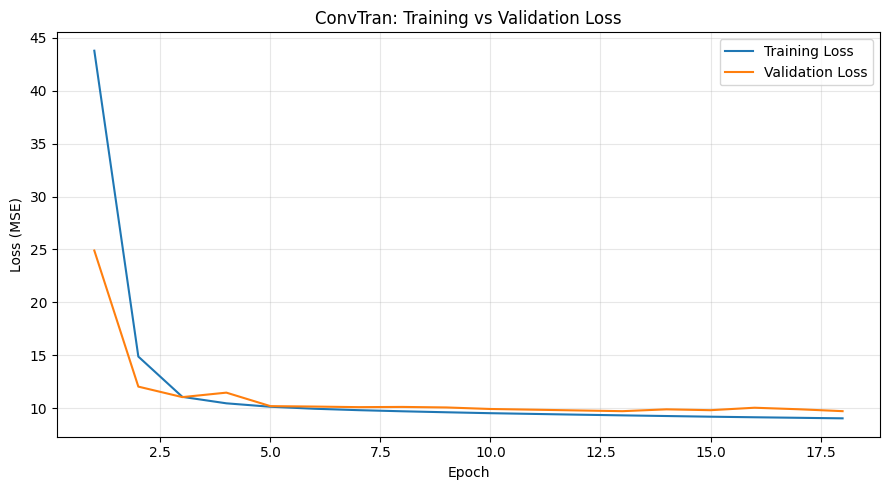

In [26]:
plot_convtran_loss(history)

In [27]:
checkpoint = torch.load(
    './checkpoints/model_best.pth',
    map_location=device
)

model.load_state_dict(checkpoint['state_dict'])
model.to(device)

test_evaluator = SupervisedTrainer(
    model=model,
    dataloader=test_loader,
    device=device,
    loss_module=loss_module,
    optimizer=None,
    l2_reg=None,
    print_interval=10,
    console=True,
    print_conf_mat=False
)

In [28]:
test_metrics, test_results = test_evaluator.evaluate(
    epoch_num=None,
    keep_all=True
)

In [29]:
y_true = test_results['targets']
y_pred = test_results['predictions']

print("True shape:", y_true.shape)
print("Pred shape:", y_pred.shape)

True shape: (52863, 2)
Pred shape: (52863, 2)


===== SBP Metrics =====
RMSE: 18.8051
MSE : 353.6336
R²  : 0.3305
MAE : 14.1686


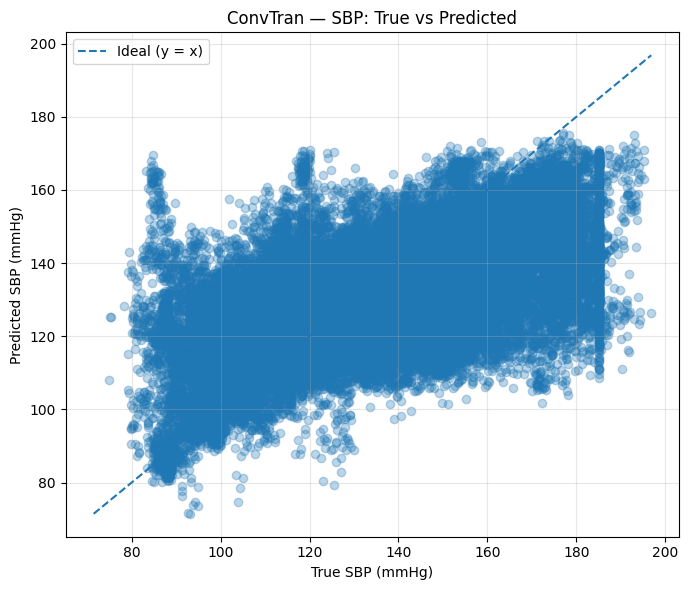

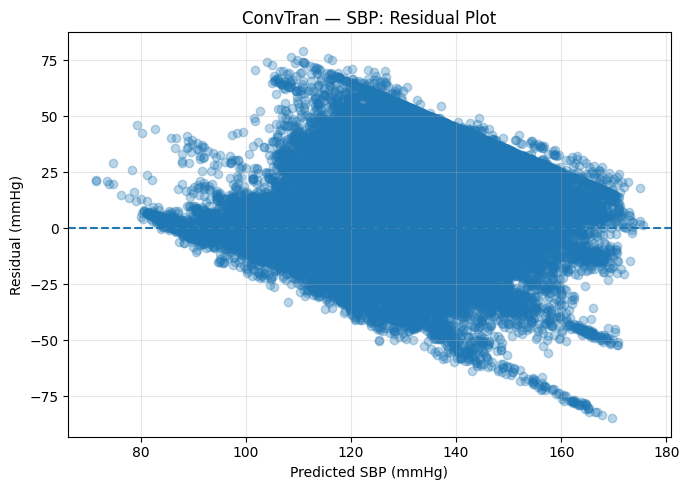

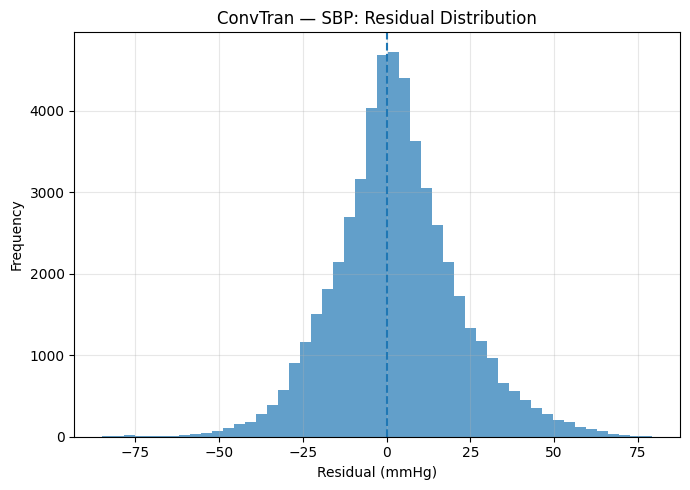

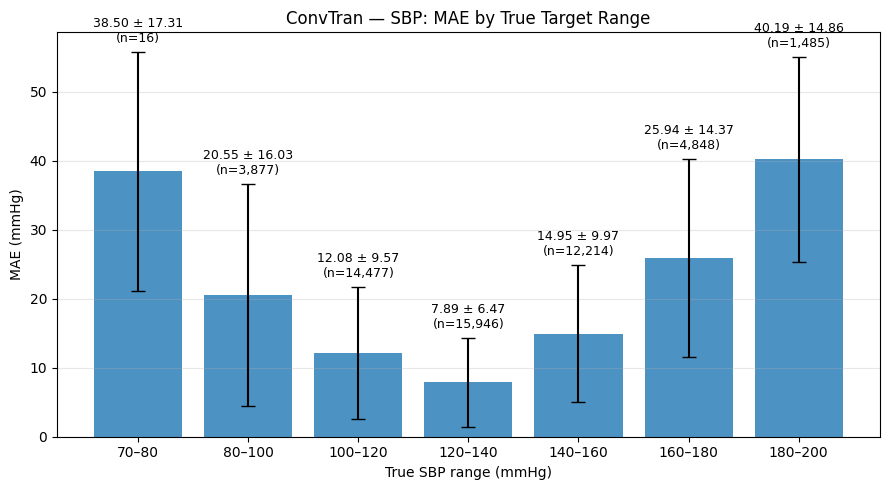

===== DBP Metrics =====
RMSE: 9.7220
MSE : 94.5181
R²  : 0.2452
MAE : 6.9629


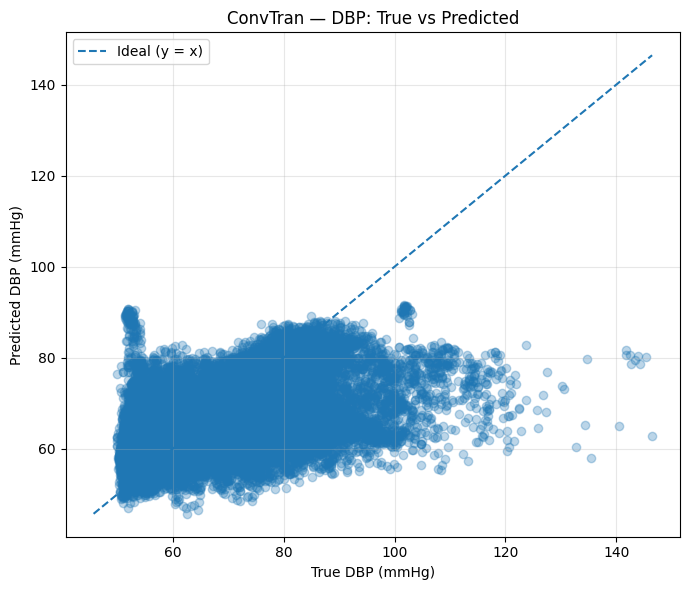

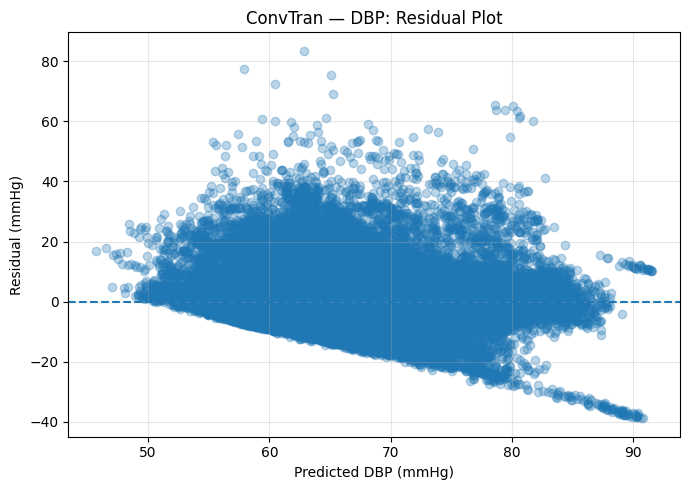

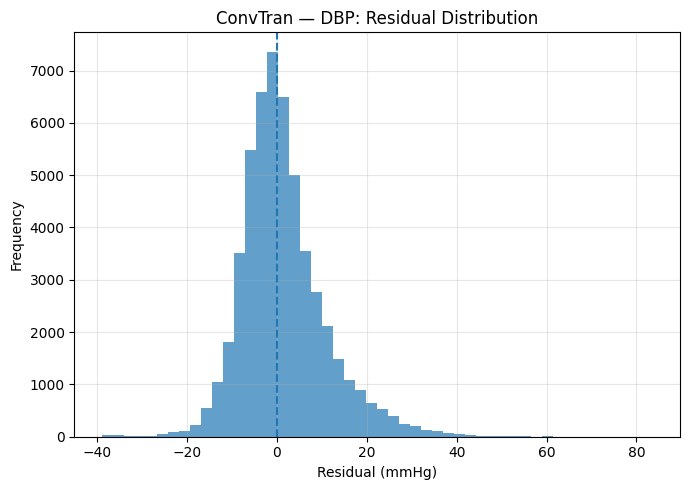

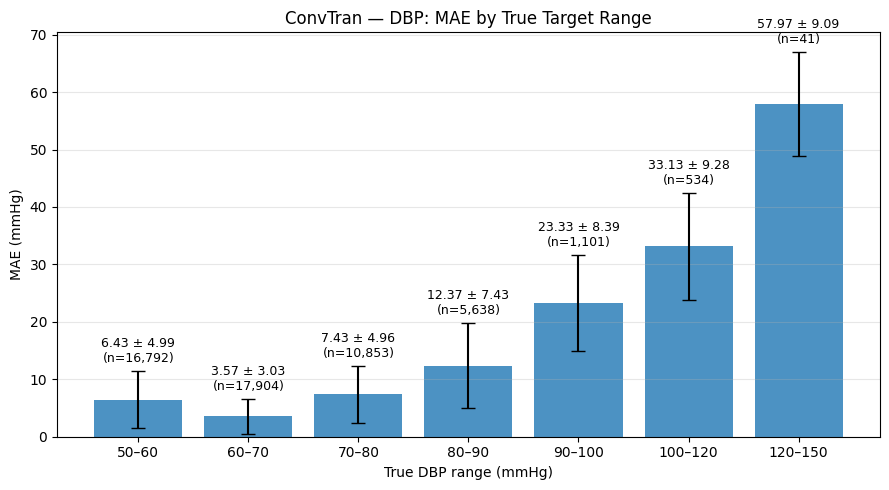

In [30]:
# Convert to NumPy arrays if they are PyTorch tensors
if torch.is_tensor(y_true):
    y_true = y_true.detach().cpu().numpy()

if torch.is_tensor(y_pred):
    y_pred = y_pred.detach().cpu().numpy()

# Extract SBP and DBP separately
sbp_true = y_true[:, 0]
sbp_pred = y_pred[:, 0]

dbp_true = y_true[:, 1]
dbp_pred = y_pred[:, 1]

# SBP metrics and plots
print("===== SBP Metrics =====")
print_metrics(sbp_true, sbp_pred)

plot_regression_results(
    sbp_true,
    sbp_pred,
    model_name="ConvTran",
    target_name="SBP"
)

# DBP metrics and plots
print("===== DBP Metrics =====")
print_metrics(dbp_true, dbp_pred)

plot_regression_results(
    dbp_true,
    dbp_pred,
    model_name="ConvTran",
    target_name="DBP"
)

Number of VitalDB cases: 1961


ConvTran VitalDB prediction: 100%|██████████| 1961/1961 [1:02:03<00:00,  1.90s/case]



CONVTRAN
VITALDB ZERO-SHOT RESULTS

SBP
RMSE: 22.1885
MSE : 492.3286
R²  : -0.1555
MAE : 17.5304

DBP
RMSE: 13.5311
MSE : 183.0911
R²  : -0.1249
MAE : 10.5542


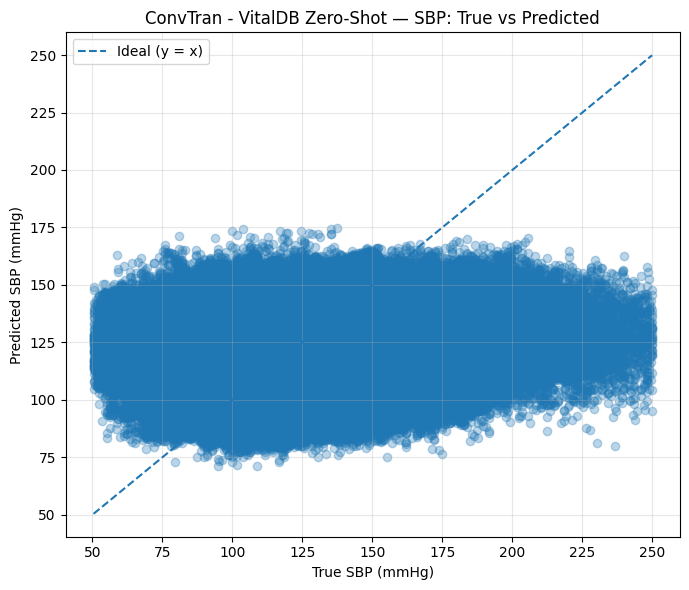

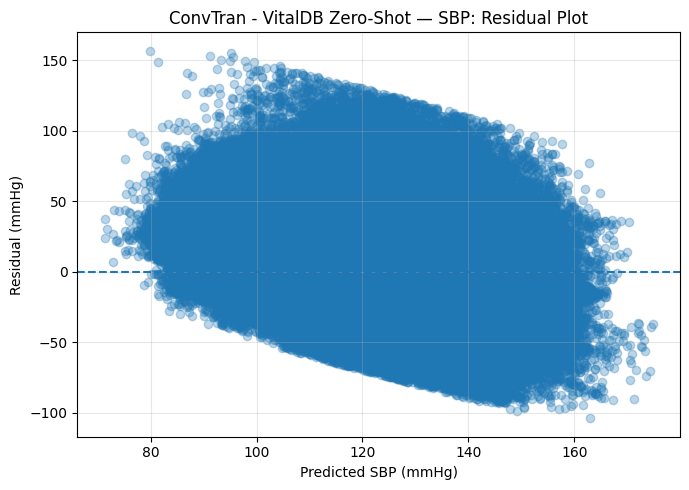

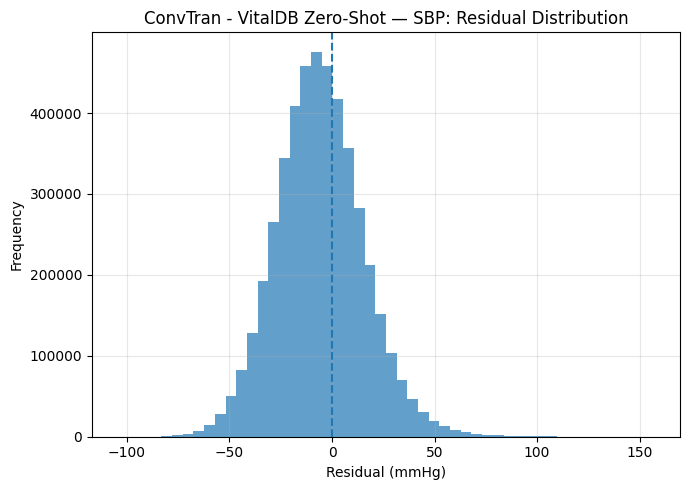

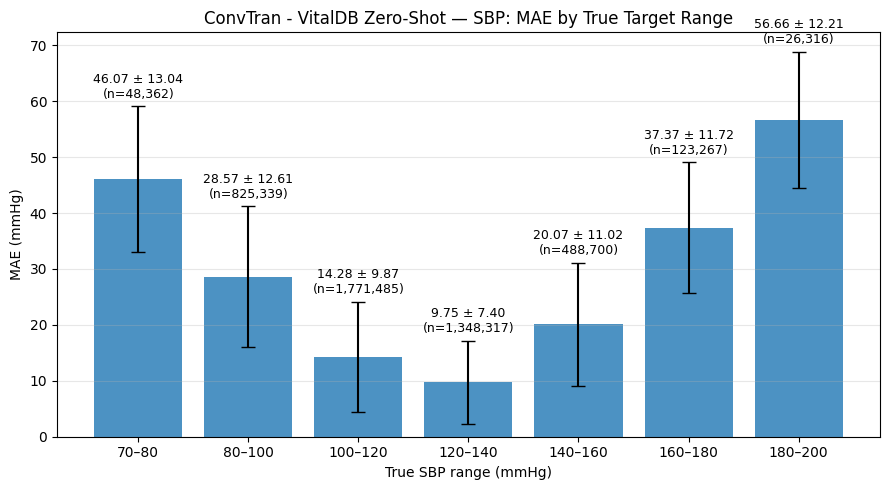

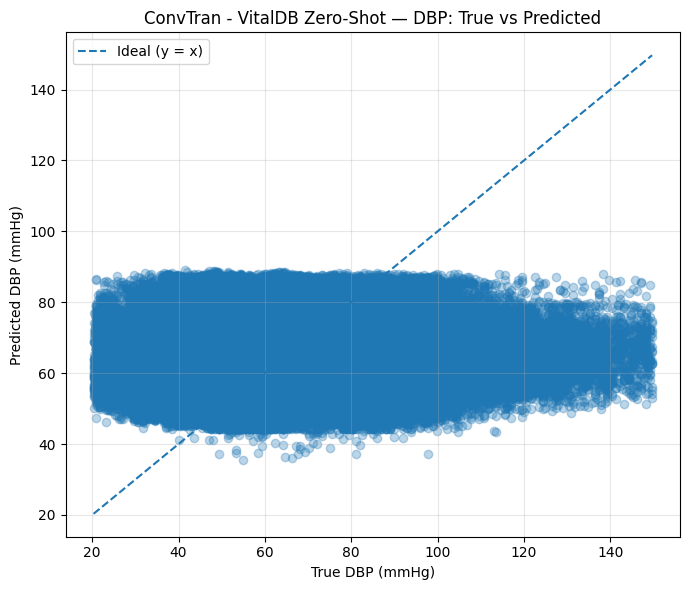

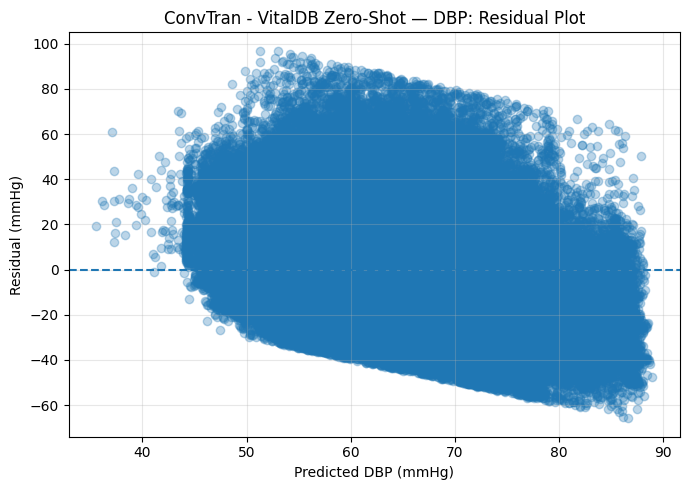

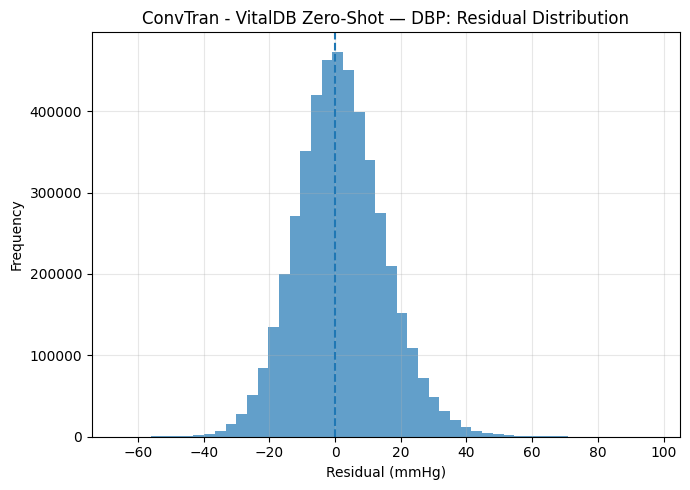

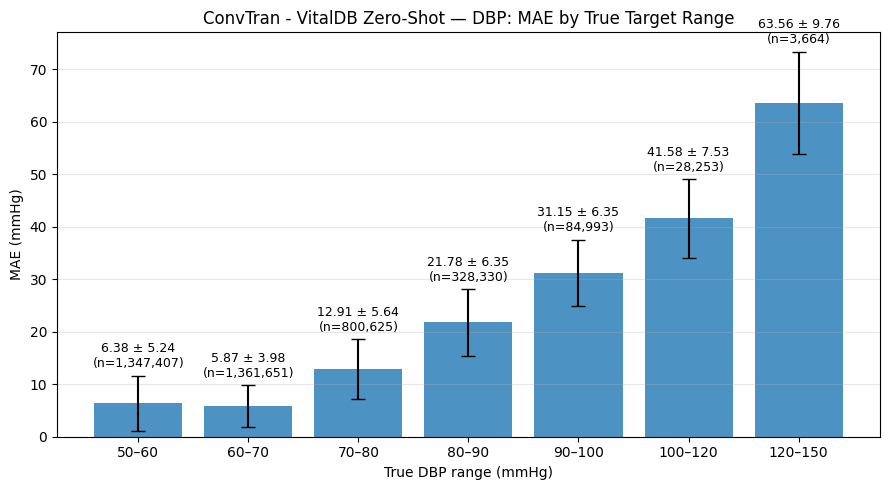

In [31]:
from processing import evaluate_convtran_vitaldb
convtran_vitaldb_results = evaluate_convtran_vitaldb(
    model=model,  # Your trained, best-checkpoint ConvTran model
    base_dir=BASE_DIR,
    batch_size=64,
    device=device
)